# 6장. 불량 위험 분석 및 모델 최적화

5장의 두 후보 모델을 끝까지 비교합니다.
- LR + SelectKBest: 개발 데이터 시간 교차검증 2위, 가장 단순한 축
- XGBoost (Optuna): 개발 데이터 시간 교차검증 1위

SHAP 설명, 확률 보정, 비용 기반 임계값을 모두 **개발 데이터의 OOF 예측**으로 정하고,
평가 데이터에는 결정된 규칙을 그대로 적용만 합니다.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/01-yield-risk
    !pip install -q shap

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import xgboost
from sklearn.calibration import calibration_curve
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.secom_utils import SEED, dev_test_split, load_secom, make_preprocessor, oof_predict, time_folds

warnings.filterwarnings("ignore", category=UserWarning)
ENV = {"python": platform.python_version(), "sklearn": sklearn.__version__,
       "xgboost": xgboost.__version__, "shap": shap.__version__}
print(ENV)

{'python': '3.12.9', 'sklearn': '1.9.1', 'xgboost': '3.4.1', 'shap': '0.54.1'}


In [3]:
X, y, ts = load_secom()
(X_dev, y_dev, ts_dev), (X_test, y_test, ts_test) = dev_test_split(X, y, ts, test_size=0.2)
FOLDS = time_folds(len(y_dev), start=0.4, k=3)
models_json = json.loads(Path("results/05_models.json").read_text(encoding="utf-8"))
K = int(models_json["lr_selected"]["k"])
C = float(models_json["lr_selected"]["C"])
XGB_PARAMS = models_json["optuna"]["best_params"]
print("LR:", K, C, "| XGB:", XGB_PARAMS)


def make_lr(pos_weight=None):
    return Pipeline([
        ("prep", make_preprocessor(scale=True)),
        ("select", SelectKBest(f_classif, k=K)),
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=5000)),
    ])


def make_xgb(pos_weight):
    return Pipeline([
        ("prep", make_preprocessor(scale=False)),
        ("clf", XGBClassifier(**XGB_PARAMS, scale_pos_weight=pos_weight, eval_metric="aucpr",
                              n_jobs=-1, random_state=SEED)),
    ])


MAKERS = {"LR+KBest": make_lr, "XGBoost(Optuna)": make_xgb}
pw = (y_dev == 0).sum() / y_dev.sum()
fitted = {name: make(pw).fit(X_dev, y_dev) for name, make in MAKERS.items()}
oof = {name: oof_predict(make, X_dev, y_dev, FOLDS) for name, make in MAKERS.items()}
test_p = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}

LR: 80 0.1 | XGB: {'n_estimators': 250, 'max_depth': 3, 'learning_rate': 0.010043634638972627, 'subsample': 0.7078327809961652, 'colsample_bytree': 0.5615469993896111, 'min_child_weight': 2.4644935099526593, 'reg_lambda': 1.2621580647749633}


## 6-1. SHAP 기반 모델 설명

XGBoost mean|SHAP| 상위 10개
f059    0.4376
f460    0.1078
f033    0.0768
f519    0.0618
f290    0.0529
f247    0.0512
f445    0.0500
f031    0.0473
f000    0.0445
f019    0.0398
dtype: float32


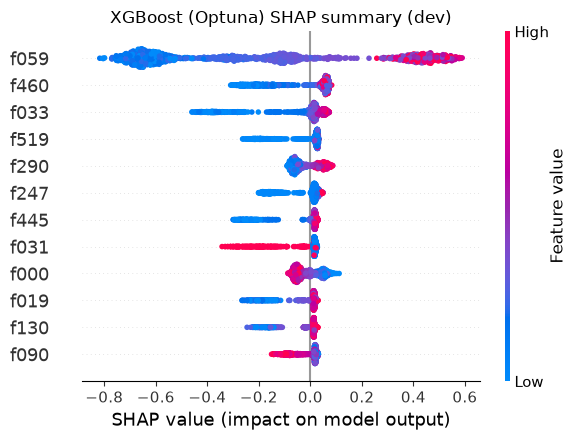

In [4]:
xgb_pipe = fitted["XGBoost(Optuna)"]
prep = xgb_pipe.named_steps["prep"]
feat_names = prep.get_feature_names_out(X_dev.columns)
Z_dev = prep.transform(X_dev)
explainer = shap.TreeExplainer(xgb_pipe.named_steps["clf"])
sv = explainer.shap_values(Z_dev)
shap_rank = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("XGBoost mean|SHAP| 상위 10개")
print(shap_rank.head(10).round(4))

shap.summary_plot(sv, Z_dev, feature_names=list(feat_names), max_display=12, show=False, plot_size=(6, 4.5))
plt.title("XGBoost (Optuna) SHAP summary (dev)")
plt.tight_layout()
plt.savefig("results/06_shap_summary.png", dpi=150)
plt.show()

In [5]:
lr_pipe = fitted["LR+KBest"]
names_after_prep = lr_pipe.named_steps["prep"].get_feature_names_out(X_dev.columns)
selected = names_after_prep[lr_pipe.named_steps["select"].get_support()]
coef = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=selected)
lr_rank = coef.abs().sort_values(ascending=False)
print("LR |계수| 상위 10개 (표준화된 특성 기준)")
print(coef[lr_rank.index[:10]].round(3))

top_xgb, top_lr = set(shap_rank.index[:10]), set(lr_rank.index[:10])
print("두 모델 상위 10개 중 겹치는 특성:", sorted(top_xgb & top_lr))

LR |계수| 상위 10개 (표준화된 특성 기준)
f059    0.767
f021    0.589
f026    0.494
f064    0.483
f196   -0.407
f348    0.404
f334   -0.364
f460    0.354
f129    0.324
f280   -0.318
dtype: float64
두 모델 상위 10개 중 겹치는 특성: ['f059', 'f460']


In [6]:
# 안정성: 시간 교차검증 각 분할에서 학습한 XGBoost의 SHAP 상위 10개가 얼마나 같은가?
fold_tops = []
for tr, _ in FOLDS:
    y_tr = y_dev.iloc[tr]
    m = make_xgb((y_tr == 0).sum() / y_tr.sum()).fit(X_dev.iloc[tr], y_tr)
    p = m.named_steps["prep"]
    v = shap.TreeExplainer(m.named_steps["clf"]).shap_values(p.transform(X_dev.iloc[tr]))
    r = pd.Series(np.abs(v).mean(axis=0), index=p.get_feature_names_out(X_dev.columns)).sort_values(ascending=False)
    fold_tops.append(set(r.index[:10]))


def jaccard(a, b):
    return len(a & b) / len(a | b)


pairs = [(i, j) for i in range(len(fold_tops)) for j in range(i + 1, len(fold_tops))]
jac = [jaccard(fold_tops[i], fold_tops[j]) for i, j in pairs]
in_all = sorted(set.intersection(*fold_tops))
print("분할 간 상위 10개 Jaccard:", [round(v, 2) for v in jac])
print("세 분할 모두 상위 10개에 든 특성:", in_all)

분할 간 상위 10개 Jaccard: [0.33, 0.18, 0.25]
세 분할 모두 상위 10개에 든 특성: ['f000', 'f031', 'f059']


## 6-2. 예측 확률 보정과 임계값 조정

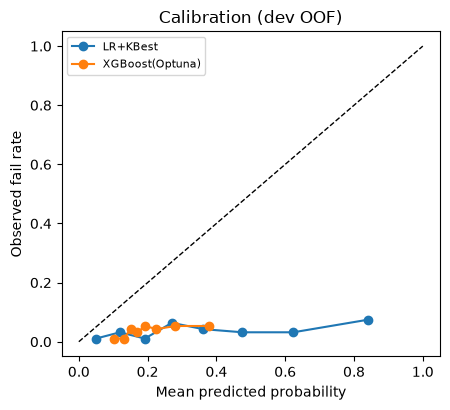

,model,oof_mean_pred,oof_fail_rate,oof_brier
0,LR+KBest,0.3667,0.0372,0.2011
1,XGBoost(Optuna),0.2038,0.0372,0.0679


In [7]:
calib_rows = []
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], "k--", lw=1)
for name, (_, yt, pt, _) in oof.items():
    frac, mean_pred = calibration_curve(yt, pt, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", label=name)
    calib_rows.append({"model": name, "oof_mean_pred": float(pt.mean()), "oof_fail_rate": float(yt.mean()),
                       "oof_brier": brier_score_loss(yt, pt)})
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fail rate")
ax.set_title("Calibration (dev OOF)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("results/06_calibration.png", dpi=150)
plt.show()
calib = pd.DataFrame(calib_rows)
calib.round(4)

In [8]:
# Platt 보정: OOF 예측으로 로지스틱 보정기를 학습해 평가 데이터 확률에 적용
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


platt_rows = []
for name, (_, yt, pt, _) in oof.items():
    cal = LogisticRegression().fit(logit(pt), yt)   # OOF로 보정기 학습

    def calibrate(p, cal=cal):
        return cal.predict_proba(logit(p))[:, 1]

    pt_test = test_p[name]
    platt_rows.append({
        "model": name,
        "test_brier_raw": brier_score_loss(y_test, pt_test),
        "test_brier_platt": brier_score_loss(y_test, calibrate(pt_test)),
        "test_mean_raw": float(pt_test.mean()),
        "test_mean_platt": float(calibrate(pt_test).mean()),
        "test_fail_rate": float(y_test.mean()),
        "test_ap_raw": average_precision_score(y_test, pt_test),
        "test_ap_platt": average_precision_score(y_test, calibrate(pt_test)),
    })
pd.DataFrame(platt_rows).round(4)

,model,test_brier_raw,test_brier_platt,test_mean_raw,test_mean_platt,test_fail_rate,test_ap_raw,test_ap_platt
0,LR+KBest,0.1272,0.0514,0.2665,0.0304,0.0541,0.1351,0.1351
1,XGBoost(Optuna),0.0898,0.0513,0.2342,0.0427,0.0541,0.0699,0.0699


## 6-3. 불량 미검출 및 과잉 알람 비용

**가정**: 불량 1건을 놓치는 비용(FN)을 10, 불필요한 알람 1건(FP)의 재검사 비용을 1로 둡니다.
실제 공정의 비용 자료가 아니라 설명을 위한 가정값입니다.

In [9]:
def confusion_at(y_true, p, thr):
    pred = p >= thr
    y_true = np.asarray(y_true).astype(bool)
    return {"tp": int((pred & y_true).sum()), "fp": int((pred & ~y_true).sum()),
            "fn": int((~pred & y_true).sum()), "tn": int((~pred & ~y_true).sum())}


def cost_of(cm, c_fn, c_fp):
    return cm["fn"] * c_fn + cm["fp"] * c_fp


def best_threshold(y_true, p, c_fn, c_fp):
    cands = np.unique(np.concatenate([p, [1.01]]))
    costs = [cost_of(confusion_at(y_true, p, t), c_fn, c_fp) for t in cands]
    return float(cands[int(np.argmin(costs))])


def f1_threshold(y_true, p):
    best, best_t = -1, 0.5
    for t in np.unique(p):
        cm = confusion_at(y_true, p, t)
        f1 = 2 * cm["tp"] / max(2 * cm["tp"] + cm["fp"] + cm["fn"], 1)
        if f1 > best:
            best, best_t = f1, float(t)
    return best_t


C_FN, C_FP = 10, 1
thr_rows = []
for name, (_, yt, pt, _) in oof.items():
    rules = {"0.5 (default)": 0.5, "max F1 (OOF)": f1_threshold(yt, pt), f"min cost {C_FN}:{C_FP} (OOF)": best_threshold(yt, pt, C_FN, C_FP)}
    for rule, thr in rules.items():
        cm = confusion_at(y_test, test_p[name], thr)
        thr_rows.append({"model": name, "rule": rule, "threshold": thr, **cm,
                         "recall": cm["tp"] / max(cm["tp"] + cm["fn"], 1),
                         "precision": cm["tp"] / max(cm["tp"] + cm["fp"], 1),
                         "alarms_per_100": 100 * (cm["tp"] + cm["fp"]) / len(y_test),
                         "test_cost": cost_of(cm, C_FN, C_FP)})
n_fail, n_pass = int(y_test.sum()), int((y_test == 0).sum())
baselines = {"no alarm (cost)": n_fail * C_FN, "alarm all (cost)": n_pass * C_FP}
print("기준선 비용 — 알람 없음:", baselines["no alarm (cost)"], "| 전수 알람:", baselines["alarm all (cost)"])
thr_table = pd.DataFrame(thr_rows)
thr_table.round(3)

기준선 비용 — 알람 없음: 170 | 전수 알람: 297


,model,rule,threshold,tp,fp,fn,tn,recall,precision,alarms_per_100,test_cost
0,LR+KBest,0.5 (default),0.500,4,40,13,257,0.235,0.091,14.013,170
1,LR+KBest,max F1 (OOF),0.819,2,3,15,294,0.118,0.400,1.592,153
2,LR+KBest,min cost 10:1 (OOF),0.993,0,1,17,296,0.000,0.000,0.318,171
3,XGBoost(Optuna),0.5 (default),0.500,0,3,17,294,0.000,0.000,0.955,173
4,XGBoost(Optuna),max F1 (OOF),0.524,0,2,17,295,0.000,0.000,0.637,172
5,XGBoost(Optuna),min cost 10:1 (OOF),0.524,0,2,17,295,0.000,0.000,0.637,172


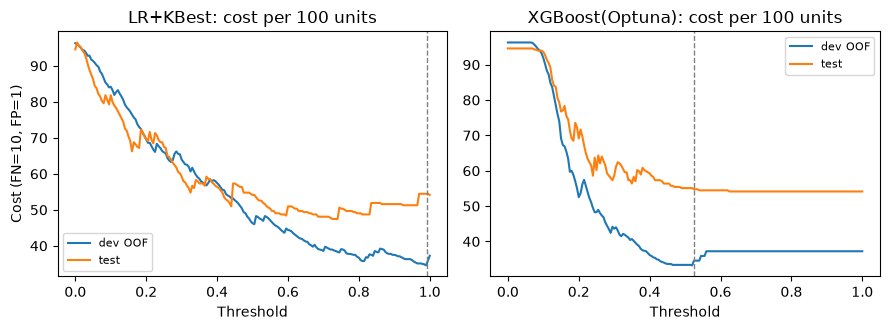

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
grid_t = np.linspace(0.0, 1.0, 201)
for ax, (name, (_, yt, pt, _)) in zip(axes, oof.items()):
    oof_cost = [cost_of(confusion_at(yt, pt, t), C_FN, C_FP) / len(yt) * 100 for t in grid_t]
    test_cost = [cost_of(confusion_at(y_test, test_p[name], t), C_FN, C_FP) / len(y_test) * 100 for t in grid_t]
    ax.plot(grid_t, oof_cost, label="dev OOF")
    ax.plot(grid_t, test_cost, label="test")
    t_star = best_threshold(yt, pt, C_FN, C_FP)
    ax.axvline(t_star, color="gray", ls="--", lw=1)
    ax.set_title(f"{name}: cost per 100 units")
    ax.set_xlabel("Threshold")
    ax.legend(fontsize=8)
axes[0].set_ylabel(f"Cost (FN={C_FN}, FP={C_FP})")
fig.tight_layout()
fig.savefig("results/06_cost_vs_threshold.png", dpi=150)
plt.show()

In [11]:
# 비용 비율 민감도: FN 비용을 바꾸면 OOF로 고른 임계값과 평가 비용이 어떻게 달라지는가?
sens = []
for ratio in [2, 5, 10, 20, 50]:
    for name, (_, yt, pt, _) in oof.items():
        thr = best_threshold(yt, pt, ratio, 1)
        cm = confusion_at(y_test, test_p[name], thr)
        sens.append({"fn_cost": ratio, "model": name, "threshold": thr, **cm,
                     "test_cost": cost_of(cm, ratio, 1),
                     "no_alarm": n_fail * ratio, "alarm_all": n_pass})
sens = pd.DataFrame(sens)
sens.round(3)

,fn_cost,model,threshold,tp,fp,fn,tn,test_cost,no_alarm,alarm_all
0,2,LR+KBest,0.993,0,1,17,296,35,34,297
1,2,XGBoost(Optuna),0.524,0,2,17,295,36,34,297
2,5,LR+KBest,0.993,0,1,17,296,86,85,297
3,5,XGBoost(Optuna),0.524,0,2,17,295,87,85,297
4,10,LR+KBest,0.993,0,1,17,296,171,170,297
5,10,XGBoost(Optuna),0.524,0,2,17,295,172,170,297
6,20,LR+KBest,0.674,3,13,14,284,293,340,297
7,20,XGBoost(Optuna),0.524,0,2,17,295,342,340,297
8,50,LR+KBest,0.099,15,227,2,70,327,850,297
9,50,XGBoost(Optuna),0.154,16,234,1,63,284,850,297


## 6-4. 공정 개선 가능성 검토와 해석 한계

In [12]:
# 평가 데이터에서 놓친 불량(FN)은 예측 확률 순위가 어디쯤이었나?
name = "LR+KBest"
thr = best_threshold(*oof[name][1:3], C_FN, C_FP)
p = test_p[name]
rank = pd.Series(p).rank(ascending=False).astype(int)
fails = pd.DataFrame({"ts": ts_test, "proba": p, "rank_of_314": rank, "fail": y_test})
fails = fails[fails["fail"] == 1].sort_values("proba", ascending=False)
fails["caught"] = fails["proba"] >= thr
print(f"임계값 {thr:.3f} 기준, 불량 {len(fails)}건 중 탐지 {int(fails['caught'].sum())}건")
fails.round(3)

임계값 0.993 기준, 불량 17건 중 탐지 0건


,ts,proba,rank_of_314,fail,caught
147,2008-10-07 13:10:00,0.970,2,1,False
266,2008-10-15 02:42:00,0.831,5,1,False
110,2008-10-06 13:38:00,0.744,12,1,False
75,2008-10-05 16:49:00,0.599,24,1,False
74,2008-10-05 16:37:00,0.444,55,1,False
1,2008-10-02 21:32:00,0.442,56,1,False
71,2008-10-05 15:30:00,0.369,83,1,False
112,2008-10-06 15:00:00,0.338,93,1,False
111,2008-10-06 13:55:00,0.326,100,1,False
90,2008-10-06 03:57:00,0.220,154,1,False


In [13]:
result = {
    "env": ENV,
    "shap_top10_xgb": shap_rank.head(10).round(5).to_dict(),
    "lr_top10_coef": coef[lr_rank.index[:10]].round(4).to_dict(),
    "top10_overlap": sorted(top_xgb & top_lr),
    "fold_top10_jaccard": [round(v, 3) for v in jac],
    "fold_top10_in_all": in_all,
    "calibration_oof": calib.round(4).to_dict(orient="records"),
    "platt_test": pd.DataFrame(platt_rows).round(4).to_dict(orient="records"),
    "cost_assumption": {"fn": C_FN, "fp": C_FP},
    "baselines": baselines,
    "threshold_table": thr_table.round(4).to_dict(orient="records"),
    "sensitivity": sens.round(4).to_dict(orient="records"),
    "test_fail_ranks_lr": fails[["rank_of_314", "proba", "caught"]].round(4).to_dict(orient="records"),
}
Path("results/06_threshold_shap.json").write_text(json.dumps(result, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("saved")

saved
